# Part 5 - Portfolio Analytics

**Summary.** MSCI Value delivers measurable HML exposure (+0.322), but its more elaborate classification does not generate significant alpha (t = -0.91). A generic factor replication historically delivered a higher Sharpe (0.529 versus 0.450). The equal-weighted four-index blend improves absolute performance, but its benchmark-relative information ratio is only 0.045. Minimum Volatility is the better stand-alone risk-adjusted investment (Sharpe 0.66), although its low market beta makes it challenging for benchmark-constrained managers.



In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'pyproject.toml').exists():
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
sys.path.insert(0,str(ROOT/'src'))
from part5.analysis import load_sample, analyze, fit_factors, save_charts, OUT
OUT.mkdir(parents=True,exist_ok=True)
data=load_sample()
result, returns, active = analyze(data)
save_charts(returns,active,result)
print(f"Sample: {result['n']} months; {result['start']} to {result['end']}")

Sample: 343 months; 1995-01 to 2023-07


## 5A. MSCI Value and Fama-French value definitions

**** MSCI uses three value indicators: book value/price, 12-month forward earnings/price, and dividend yield. It separately measures growth using long- and short-term forward EPS growth, current internal growth, historical long-term EPS growth, and historical long-term sales-per-share growth. Value and growth membership can overlap, with partial style weights. MSCI's industry and universe exceptions apply **only to growth variables**: for example, historical long-term sales-per-share growth is excluded for specified financial industries, while long-term forward EPS growth is excluded for small-cap indexes.

Fama-French HML instead uses **one cheapness measure, book-to-market (B/M)**. Stocks are sorted into a 2-by-3 grid by size (small/big) and B/M (low/neutral/high), rebalanced each June. HML is the average return of high-B/M portfolios minus low-B/M portfolios across the two size groups. The low-B/M end represents growth without MSCI's separate five-signal growth score.

| Design choice | MSCI USA Value | Fama-French HML |
|---|---|---|
| Value signal | Book/price, forward earnings/price, yield | Single book-to-market ratio |
| Growth treatment | Separate five-indicator score | Low book-to-market end of sort |
| Construction | Long-only large/mid-cap style weights | Long-short 2x3 size/B/M sorts; June rebalance |
| Implication | Investable but blends style and universe decisions | Cleaner academic value premium, not directly investable |

**Exhibit 5A.** Value construction comparison, methodology applicable to the US equity universe; MSCI USA Standard and Fama-French US factor portfolios. Source: MSCI Global Investable Market Value and Growth Index Methodology (February 2021); Kenneth French Data Library factor definitions.

**Investment question:** Does the extra classification complexity earn a return premium, or merely repackage exposures? The following regression provides a direct diagnostic, not a causal answer.



In [2]:
display(pd.DataFrame({'MSCI Value':['Three value signals','Five separate growth indicators','Long-only style index'],'FF HML':['One book-to-market signal','Low B/M denotes growth','Long-short 2x3 factor spread']},index=['Value','Growth','Implementation']))

,MSCI Value,FF HML
Value,Three value signals,One book-to-market signal
Growth,Five separate growth indicators,Low B/M denotes growth
Implementation,Long-only style index,Long-short 2x3 factor spread


## 5B. Factor exposure regression

Using 343 monthly gross USD returns (January 1995-July 2023), regress MSCI USA Value on an intercept, RF, market excess return, HML and SMB. Coefficients measure exposure; conventional OLS t-statistics measure estimation precision.

| Regressor | Loading | t-statistic | Interpretation |
|---|---:|---:|---|
| Intercept (monthly %) | -0.0713 | -0.91 | No significant positive alpha |
| RF | 0.8646 | 2.79 | Cash-rate exposure estimated, not fixed |
| Market excess | 0.9480 | 76.99 | Near-market equity sensitivity |
| HML | +0.3216 | 19.68 | Strong value exposure |
| SMB | -0.1744 | -9.90 | Large-cap bias embedded in style index |

**Exhibit 5B.** OLS factor fingerprint of MSCI USA Value, January 1995-July 2023, 343 monthly observations, MSCI USA Standard and Fama-French US factors. Source: supplied MSCI and Fama-French workbook.

R-squared is **94.84%**. In a month when HML gains one percentage point, the fitted index return increases by 0.322 percentage points, holding other inputs fixed; a one-point SMB gain reduces it by 0.174 points. Thus MSCI Value is not pure HML: its large-cap tilt creates a distinct performance headwind when small caps outperform. 



In [3]:
model=fit_factors(data)
display(pd.DataFrame({'Loading':model.params,'t-statistic':model.tvalues,'p-value':model.pvalues}).round(4))
print('R-squared:',round(model.rsquared,4))

,Loading,t-statistic,p-value
const,-0.0713,-0.9058,0.3657
RF,0.8646,2.7885,0.0056
Mkt-RF,0.9480,76.9858,0.0000
HML,0.3216,19.6816,0.0000
SMB,-0.1744,-9.9046,0.0000


R-squared: 0.9484


## 5C. Enhancing factor performance

The intercept is **-0.0713% monthly** (t = -0.91, p = 0.366), equivalent to -0.86% under simple annualization. There is no statistically significant evidence that MSCI's multi-indicator value methodology adds positive risk-adjusted alpha beyond these conventional factors. 

As a robustness check following the **May 2003 methodology change**, the June 2003-July 2023 subsample gives alpha **-0.0378% monthly (t = -0.55; n = 242)**. 

**Exhibit 5C.** Full-sample and post-May-2003 intercept tests, January 1995-July 2023 and June 2003-July 2023, MSCI USA Value and Fama-French US factors. Source: supplied workbook; authors' OLS calculations.



In [4]:
post=fit_factors(data.loc['2003-06':])
display(pd.DataFrame({'Period':['Full sample','Post-May-2003'],'Monthly alpha (%)':[model.params['const'],post.params['const']],'t-statistic':[model.tvalues['const'],post.tvalues['const']]}).round(4))

,Period,Monthly alpha (%),t-statistic
0,Full sample,-0.0713,-0.9058
1,Post-May-2003,-0.0378,-0.5508


## 5D. Fund replication

The fitted zero-alpha replication is 0.8646 RF + 0.9480(Mkt-RF) + 0.3216 HML - 0.1744 SMB. Its correlation with MSCI Value is **0.974**. The replica **historically performed better**, with a higher compounded return and Sharpe, though this is in-sample and not a realizable, cost-adjusted backtest.

| Metric | MSCI Value | FF replication |
|---|---:|---:|
| Arithmetic return, annualized | 9.87% | 10.73% |
| CAGR | 9.05% | 10.05% |
| Volatility, annualized | 15.27% | 14.87% |
| Geometric-return Sharpe | 0.450 | 0.529 |

**Exhibit 5D.** Historical return, risk and growth-of-$1 comparison, January 1995-July 2023, MSCI USA Value versus fitted Fama-French US factor replication, gross USD. Source: supplied workbook; authors' calculations. Sharpe = (CAGR - geometric annualized RF)/annualized monthly volatility, consistent with Part 1.

The replica's arithmetic return advantage of **0.86 percentage points annually** equals the regression intercept with its sign reversed and annualized; that intercept is **not significant (t = -0.91)**. 

![Exhibit 5D: Growth of $1](5d_replication_growth.png)



,arithmetic_ann,geometric_ann,vol_ann,sharpe
Value,9.874,9.049,15.267,0.450
Replication,10.729,10.046,14.868,0.529


Replication correlation: 0.974


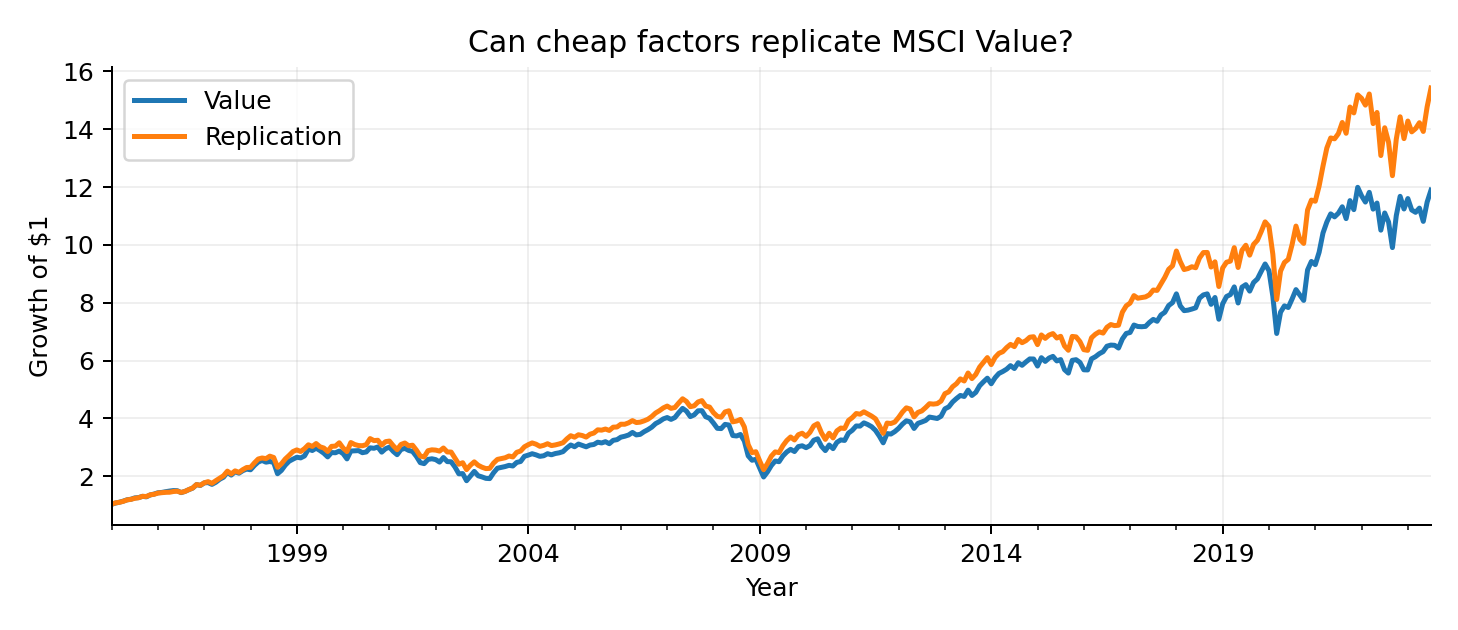

In [5]:
display(pd.DataFrame(result['portfolios']).T.round(3))
print('Replication correlation:',round(result['replication_correlation'],3))
display(Image(filename=str(OUT/'5d_replication_growth.png')))

## 5E. Relative performance analysis

For each MSCI style index, active return equals its monthly total return less MSCI USA Standard. The four-index blend is rebalanced to equal weights monthly. Annualized tracking error is monthly active-return sample standard deviation times sqrt(12); IR is annualized arithmetic active return divided by tracking error.

| Index | Active return (annual) | Tracking error | IR |
|---|---:|---:|---:|
| Value | -1.34% | 5.15% | -0.261 |
| Minimum Volatility | -0.80% | 6.38% | -0.125 |
| Equal Weight | +0.59% | 5.40% | 0.109 |
| Momentum | +2.16% | 7.73% | 0.279 |
| Four-factor blend | +0.15% | 3.39% | **0.045** |

**Exhibit 5E.** Benchmark-relative returns, tracking errors and information ratios, January 1995-July 2023, MSCI USA Value, Minimum Volatility, Equal Weight, Momentum and equal-weight blend versus MSCI USA Standard, gross USD. Source: supplied MSCI index data; authors' calculations.

**IR 0.045 is very low**, especially relative to an illustrative 0.5 benchmark for good active efficiency (verify the threshold against class notes). Its **0.15% annual arithmetic active return** averages monthly differences; its **0.34 percentage-point geometric CAGR advantage** compares two separately compounded wealth paths. 

![Exhibit 5E: Cumulative active return](5e_active_returns.png)



,annual_excess,tracking_error,information_ratio
Value,-1.343,5.154,-0.261
MinVol,-0.796,6.380,-0.125
EqualWeight,0.588,5.396,0.109
Momentum,2.158,7.730,0.279
MultiFactor,0.152,3.387,0.045


Geometric CAGR spread (percentage points): 0.336


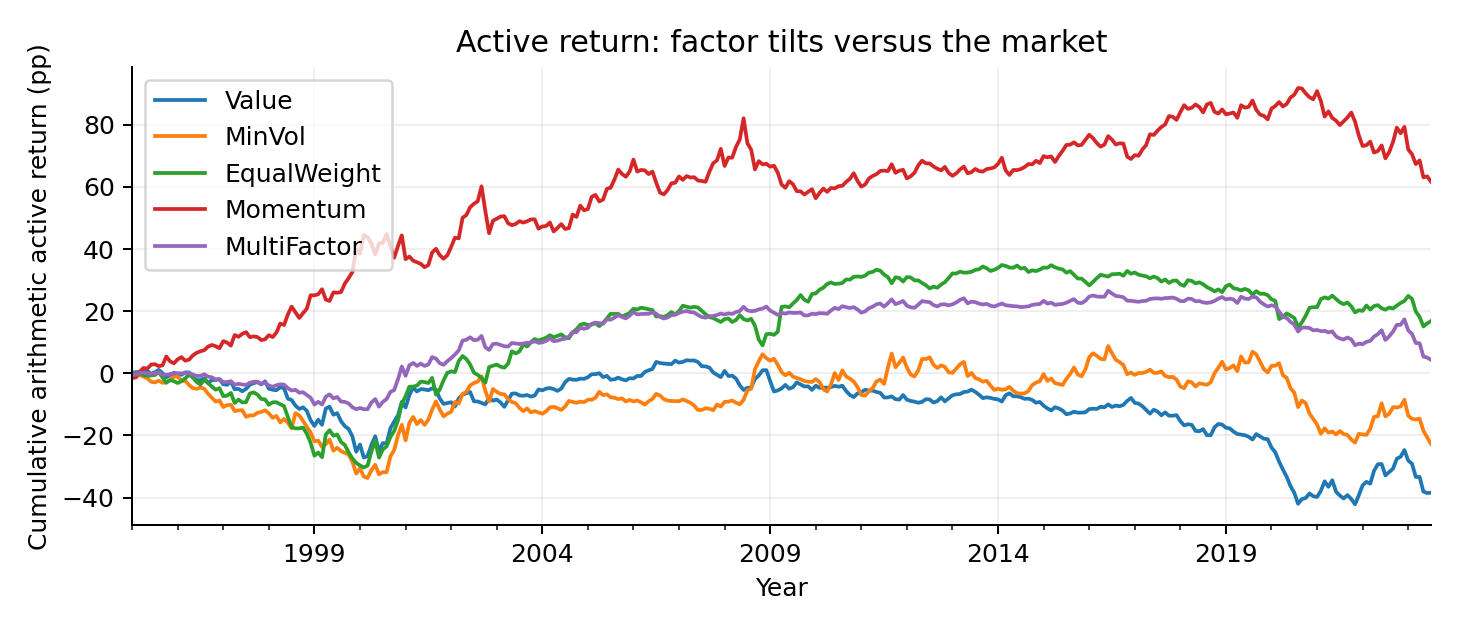

In [6]:
display(pd.DataFrame(result['active']).T.round(3))
print('Geometric CAGR spread (percentage points):',round(result['geometric_active_spread'],3))
display(Image(filename=str(OUT/'5e_active_returns.png')))

## 5F. Risk decomposition and investment decision

For four equal-weight active returns a_i, blend a_p = (1/4) sum_i a_i. Each factor's signed share of active-return variance is Cov(a_i, a_p) / [4 Var(a_p)]; shares sum to 100%. 

| Factor | Share of active-return variance |
|---|---:|
| Value | 23.26% |
| Minimum Volatility | 34.08% |
| Equal Weight | 17.86% |
| Momentum | 24.81% |

**Exhibit 5F.** Covariance contributions to four-factor blend tracking-error variance, January 1995-July 2023, MSCI USA smart-beta indexes relative to MSCI USA Standard, gross USD. Source: supplied MSCI data; authors' calculations.

![Exhibit 5F: Tracking-error contributions](5f_tracking_error_decomposition.png)

**Decision: Minimum Volatility is better as a stand-alone investment.** Its Sharpe of **0.66** is the highest among the MSCI indexes examined in Part 1, even though its IR is **-0.125** with **6.38% tracking error**. Its market beta is approximately **0.72**, so it tends to lag when the equity market rises sharply. This creates a **limits-to-arbitrage** problem: a benchmarked manager can recognize superior stand-alone risk-adjusted returns yet be penalized for tracking error and relative underperformance before the thesis pays off. 

**Methods and caveats.** MSCI index levels are converted to monthly returns; all results use January 1995-July 2023 gross USD data. Factor replication is fitted and evaluated on the same observations. Conventional OLS inference is unadjusted for autocorrelation. All investment comparisons exclude trading and financing costs. The class-specific IR threshold and limits-to-arbitrage framing should be cross-checked against lecture notes, which were not supplied.


,Variance contribution (%)
Value,23.26
MinVol,34.08
EqualWeight,17.86
Momentum,24.81


Minimum Volatility beta: 0.721


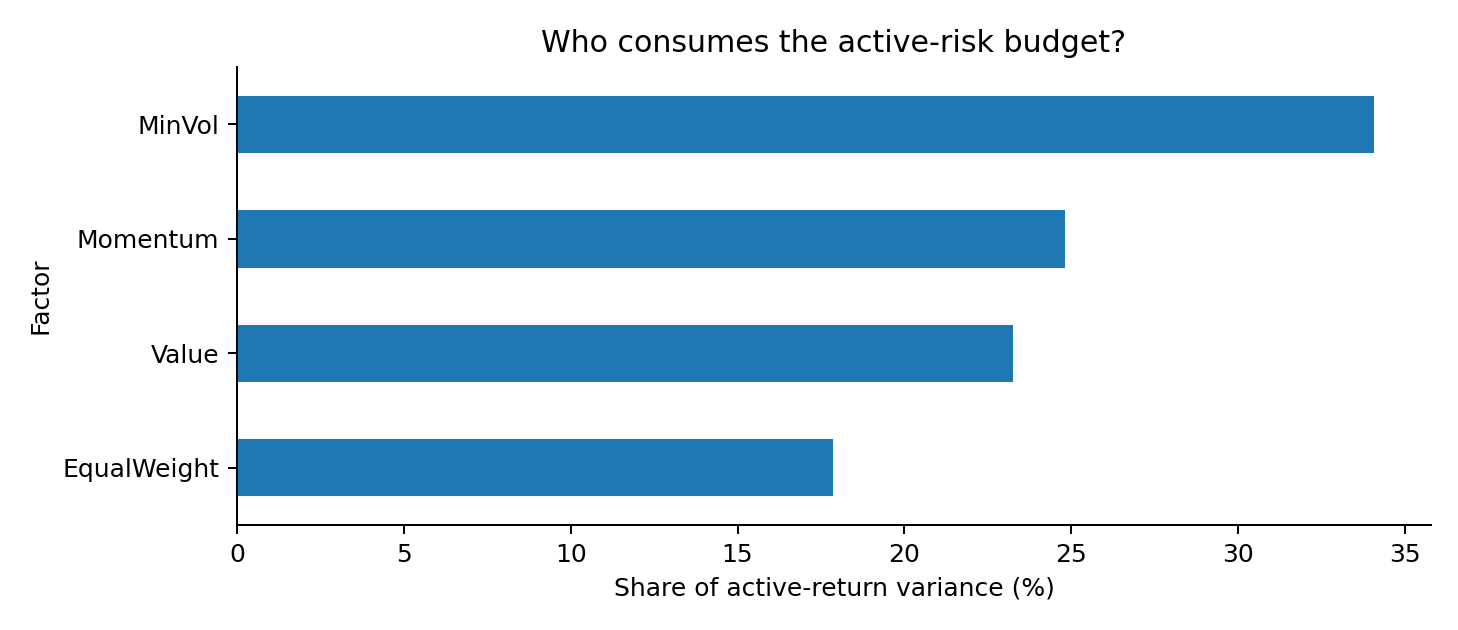

In [7]:
display(pd.Series(result['variance_contributions']).mul(100).to_frame('Variance contribution (%)').round(2))
print('Minimum Volatility beta:',round(result['minvol_beta'],3))
display(Image(filename=str(OUT/'5f_tracking_error_decomposition.png')))